# Session Variability: Pre- vs Post-Lesion (SLEAP-only fallback)

**R5/2026_09_10_1** (post-DLS-lesion, reportedly a strong-performing session) has SLEAP data
(triangulated keypoints, behavior log, a new `R5_template_7.npz`) but no DANNCE 3D
reconstruction yet -- only raw multi-camera video exists under `dannce/videos/`. The
native-DANNCE pipeline in `session_variability.ipynb` / `clirb.native_dannce` has nothing
to project, so this notebook uses `clirb.sleap_variability.build_session_variability_sleap`
instead: the same detect -> align -> window -> variability -> reward-label logic, but
staying at SLEAP's own native 20 Hz rate (with its z-flip convention) instead of upsampling
to DANNCE's 50 Hz -- there's no DANNCE data to upsample to.

**Caveat, load-bearing:** these numbers are NOT comparable in absolute units to any of the
DANNCE-based results elsewhere in this project (different camera system, frame rate, and
effectively a different feature stream through the same template weights). They are only
meaningful compared against each other, run through this SAME fallback -- which is exactly
what this notebook does: **R5/2026_07_27_1** (the strongest-performing PRE-lesion session,
used throughout this project's video/report work) vs. **R5/2026_09_10_1** (POST-lesion),
both reprocessed through the SLEAP-only path for a fair comparison.

Question: does the DLS lesion affect the reward-locked variability modulation established
pre-lesion (rewarded rears reliably less variable than unrewarded ones)?

In [1]:
import sys, os
sys.path.insert(0, '.')

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

from clirb.sleap_variability import build_session_variability_sleap, SLEAP_FPS

%matplotlib inline

SESSIONS = [('pre',  'R5', '2026_07_27_1', 'PRE-lesion (best)'),
           ('post', 'R5', '2026_09_10_1', 'POST-lesion')]
N_PCS = 3

D = {}
for key, rat, session, label in SESSIONS:
    D[key] = build_session_variability_sleap(rat, session)
    D[key]['label'] = f'{label}\n{rat}/{session}'

for key, rat, session, label in SESSIONS:
    d = D[key]
    print(f"{label:24s} {rat}/{session}: n_rears={d['n_rears']:3d}  n_valid={d['n_valid']:3d}  "
         f"matched={int(d['rear_is_matched_valid'].sum()):3d}  "
         f"template_like={int(d['rear_is_template_like_valid'].sum()):3d}  "
         f"rewarded={int(d['is_rewarded'].sum()):3d}  "
         f"duration={d['session_duration_min']:.1f}min")


PRE-lesion (best)        R5/2026_07_27_1: n_rears=250  n_valid=248  matched=112  template_like=152  rewarded=101  duration=30.0min
POST-lesion              R5/2026_09_10_1: n_rears=125  n_valid=125  matched= 82  template_like= 89  rewarded= 58  duration=30.0min


## 1. Rewarded vs unrewarded rears -- mean +/- std trajectory

Rows: pre-lesion (top) vs post-lesion (bottom). Columns: PC1/PC2/PC3.

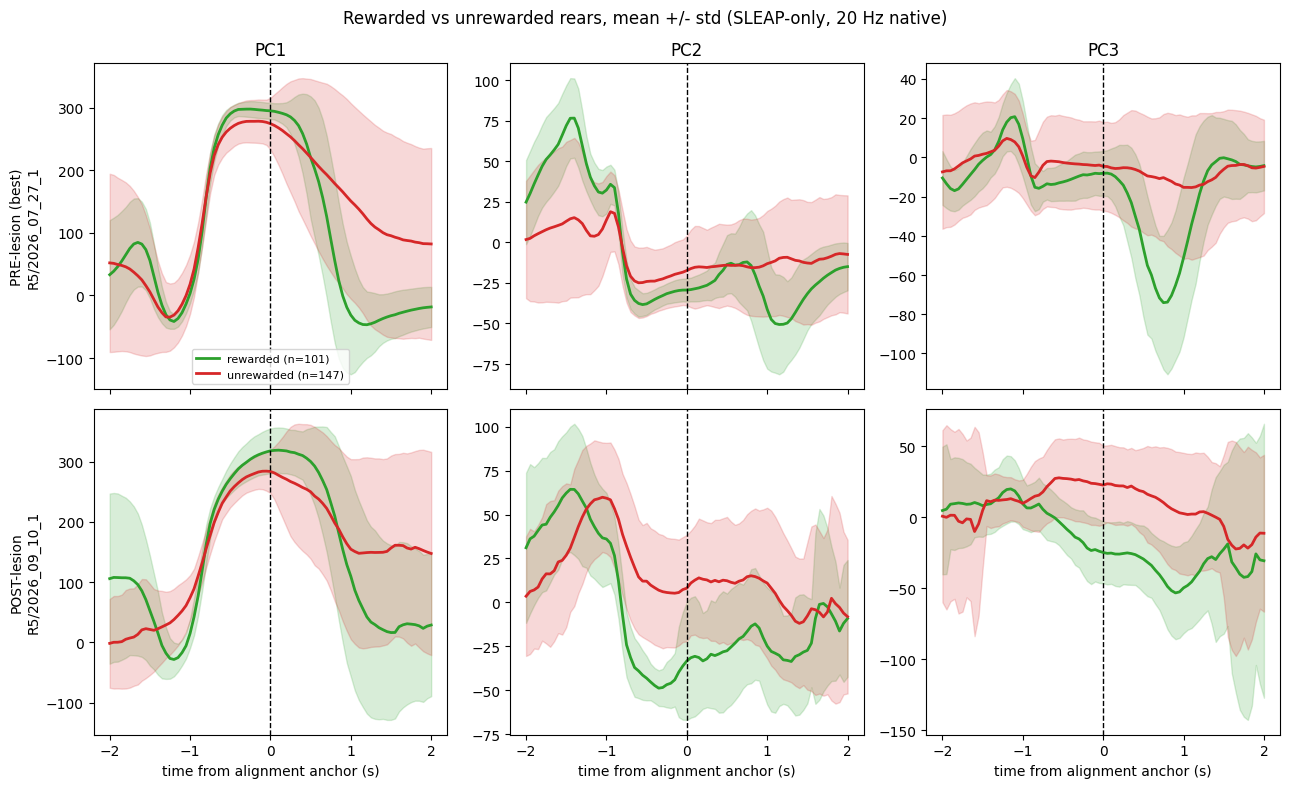

In [2]:
HALF_WIN_FRAMES = int(round(2.0 * SLEAP_FPS))
t_axis_s = (np.arange(2 * HALF_WIN_FRAMES + 1) - HALF_WIN_FRAMES) / SLEAP_FPS

fig, axes = plt.subplots(2, N_PCS, figsize=(13, 8), sharex=True)
for row_i, key in enumerate(['pre', 'post']):
    d = D[key]
    is_rewarded = d['is_rewarded']
    for pidx in range(N_PCS):
        ax = axes[row_i, pidx]
        for mask, color, name in [(is_rewarded, '#2ca02c', 'rewarded'),
                                    (~is_rewarded, '#d62728', 'unrewarded')]:
            if not mask.any():
                continue
            segs = np.stack([d['pcs_windows'][i][:, pidx] for i in np.where(mask)[0]])
            m, s = segs.mean(axis=0), segs.std(axis=0)
            ax.plot(t_axis_s, m, lw=2, color=color, label=f'{name} (n={int(mask.sum())})')
            ax.fill_between(t_axis_s, m - s, m + s, color=color, alpha=0.18)
        ax.axvline(0, color='k', ls='--', lw=1)
        if row_i == 0:
            ax.set_title(f'PC{pidx + 1}')
        if pidx == 0:
            ax.set_ylabel(d['label'])
        if row_i == 1:
            ax.set_xlabel('time from alignment anchor (s)')
        if row_i == 0 and pidx == 0:
            ax.legend(fontsize=8, loc='best')
fig.suptitle('Rewarded vs unrewarded rears, mean +/- std (SLEAP-only, 20 Hz native)', fontsize=12)
fig.tight_layout()
plt.show()


## 2. Scalar comparison -- sliding-window variability by reward presence/absence

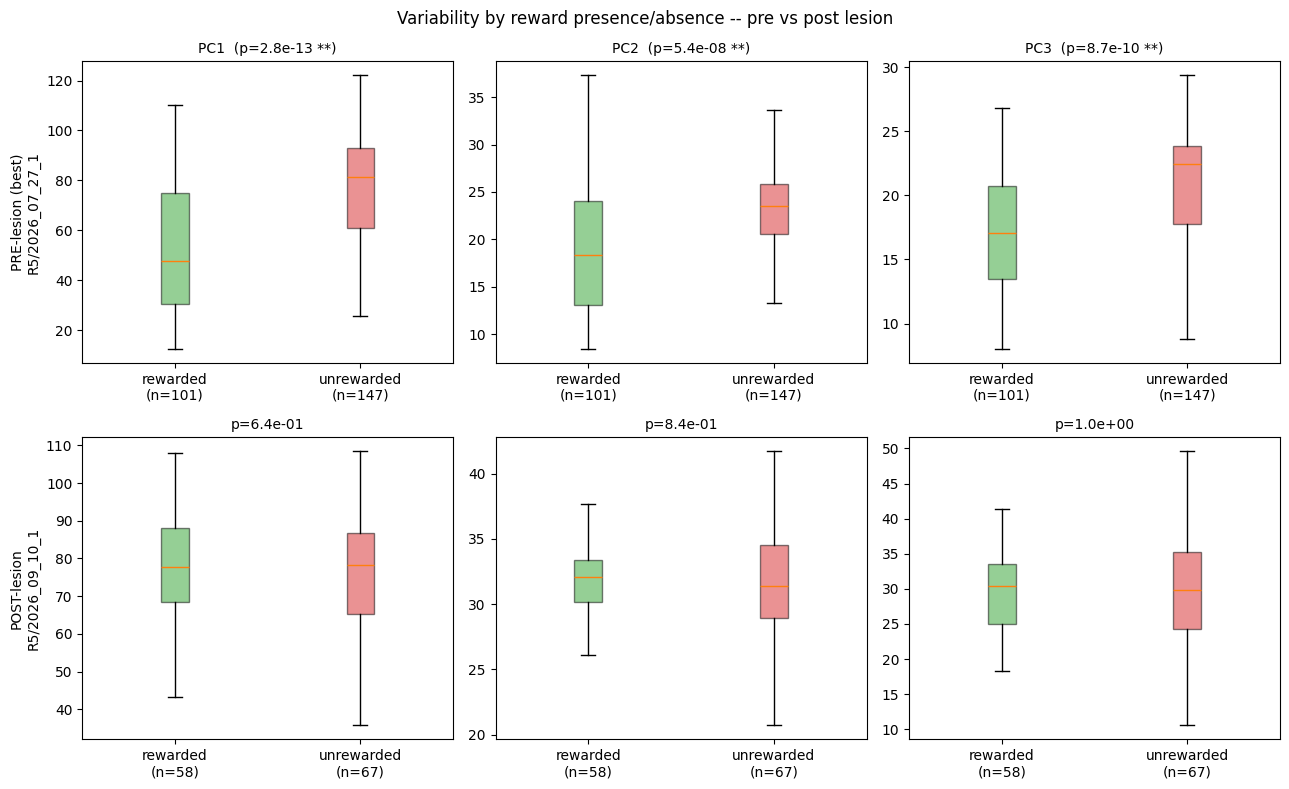

In [3]:
fig, axes = plt.subplots(2, N_PCS, figsize=(13, 8))
for row_i, key in enumerate(['pre', 'post']):
    d = D[key]
    is_rewarded = d['is_rewarded']
    for pidx in range(N_PCS):
        ax = axes[row_i, pidx]
        groups = [d['variability'][is_rewarded, pidx], d['variability'][~is_rewarded, pidx]]
        bp = ax.boxplot(groups, tick_labels=[f'rewarded\n(n={len(groups[0])})',
                                             f'unrewarded\n(n={len(groups[1])})'],
                        patch_artist=True, showfliers=False)
        for patch, color in zip(bp['boxes'], ['#2ca02c', '#d62728']):
            patch.set_facecolor(color); patch.set_alpha(0.5)
        stat, p = mannwhitneyu(*groups)
        sig = ' **' if p < 0.05 else ''
        if row_i == 0:
            ax.set_title(f'PC{pidx + 1}  (p={p:.1e}{sig})', fontsize=10)
        else:
            ax.set_title(f'p={p:.1e}{sig}', fontsize=10)
        if pidx == 0:
            ax.set_ylabel(d['label'])
fig.suptitle('Variability by reward presence/absence -- pre vs post lesion', fontsize=12)
fig.tight_layout()
plt.show()


## 3. Does variability recover with time since the last reward?

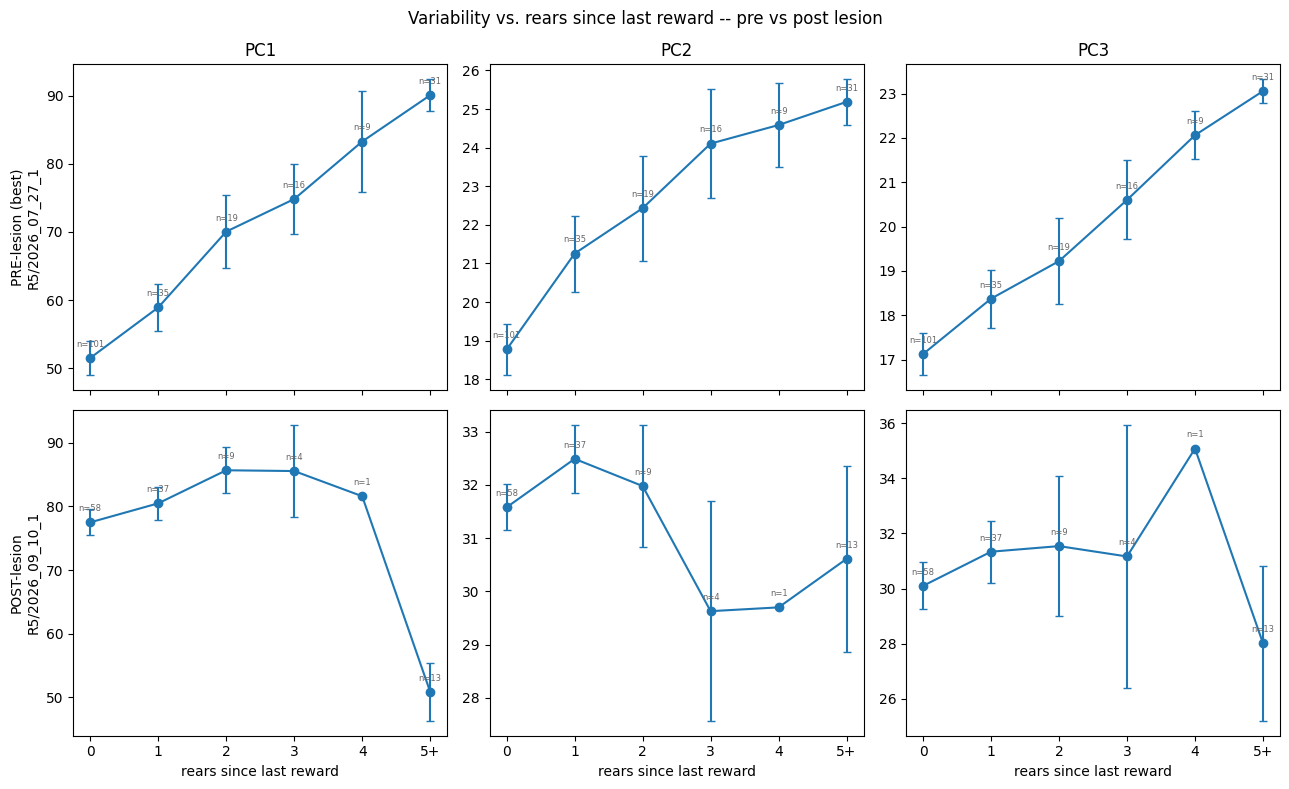

In [4]:
BIN_EDGES = [0, 1, 2, 3, 4, 5, np.inf]
BIN_LABELS = ['0', '1', '2', '3', '4', '5+']

fig, axes = plt.subplots(2, N_PCS, figsize=(13, 8), sharex=True)
for row_i, key in enumerate(['pre', 'post']):
    d = D[key]
    rsr = d['rears_since_reward']
    after_reward = rsr >= 0
    bin_idx = np.digitize(rsr[after_reward], BIN_EDGES[1:-1], right=False)
    for pidx in range(N_PCS):
        ax = axes[row_i, pidx]
        means, sems, ns = [], [], []
        for b in range(len(BIN_LABELS)):
            vals = d['variability'][after_reward, pidx][bin_idx == b]
            means.append(vals.mean() if len(vals) else np.nan)
            sems.append(vals.std(ddof=1) / np.sqrt(len(vals)) if len(vals) > 1 else 0.0)
            ns.append(len(vals))
        xs = np.arange(len(BIN_LABELS))
        ax.errorbar(xs, means, yerr=sems, marker='o', color='#1f77b4', capsize=3)
        for x, n, m in zip(xs, ns, means):
            if np.isfinite(m):
                ax.annotate(f'n={n}', (x, m), textcoords='offset points', xytext=(0, 8),
                           fontsize=6, ha='center', color='0.4')
        ax.set_xticks(xs)
        ax.set_xticklabels(BIN_LABELS)
        if row_i == 0:
            ax.set_title(f'PC{pidx + 1}')
        if pidx == 0:
            ax.set_ylabel(d['label'])
        if row_i == 1:
            ax.set_xlabel('rears since last reward')
fig.suptitle('Variability vs. rears since last reward -- pre vs post lesion', fontsize=12)
fig.tight_layout()
plt.show()


## Summary

**Pre-lesion (R5/2026_07_27_1):** reward-locked variability modulation is strong and highly
significant across all 3 PCs (p=2.8e-13, 5.4e-8, 8.7e-10) -- rewarded rears are much
tighter than unrewarded ones, and variability climbs smoothly and monotonically with rears
since the last reward (PC1: 51 &rarr; 90 over 5 bins). This matches the DANNCE-based result
established elsewhere in this project, and confirms the SLEAP-only fallback recovers the
same qualitative pattern on the same session used as this project's running example.

**Post-lesion (R5/2026_09_10_1):** the effect is **gone**. Rewarded vs. unrewarded
variability is indistinguishable on every PC (p=0.64, 0.84, 1.00 -- PC3 is essentially
exactly null). The recovery curve is flat rather than climbing, and even trends the wrong
way at the far end (though n=13 there is small). The mean+/-std trajectories show the
post-anchor separation between rewarded (green) and unrewarded (red) that's visible
pre-lesion largely collapsing post-lesion, and for PC3 even reversing sign.

This session is not a fluke of poor behavior -- it has a substantial match rate (82/125
matched, 89/125 template-like, actually a HIGHER fraction than the pre-lesion session:
66-71% vs. 45-61%) and 58 rewards over 30 minutes, so the animal is still performing the
trained motif reliably and getting reinforced for it. What's missing is specifically the
*coupling* between reward and subsequent behavioral tightening -- consistent with a role
for DLS in translating reward into reduced motor variability, rather than in the motor
pattern or reward-detection itself.

**Caveat:** n=1 session per condition; this is a single before/after comparison on the
SLEAP-only fallback, not the validated DANNCE pipeline. Worth confirming once this
session's DANNCE reconstruction lands, and ideally replicating on additional post-lesion
sessions before treating this as a settled result.